## A1 · Python basics

Jupyter, arithmetic, variables, printing and the error messages encountered most often.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Plot defaults: wide 16:9 figures, sharp ("retina") output and slightly smaller text
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (6.4, 3.6),
    "figure.dpi": 100,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

# Same data as sns.load_dataset('penguins'), saved locally so it works offline
df_penguins = pd.read_csv("data/penguins.csv")

### Using Jupyter

#### Running a cell

**A1.01**

`Shift + Enter`

Pressing `Shift+Enter` allows us to run the code in a cell and see its result immediately. It is useful when an idea is tested one step at a time. Alternatively, the ▶ button or *Run All* runs the whole notebook.

A code cell runs when **Shift+Enter** is pressed (or the ▶ button is clicked). The value of the *last line* of the cell is displayed underneath.

In [2]:
2 + 3

5

Only the last line of a cell is displayed automatically; the first line below is calculated but not shown:

In [3]:
10 * 10
20 * 20

400

Watch out: earlier lines show output only if they are printed with `print`. Each `print` starts a new line of output.

In [4]:
print(10 * 10)
print(20 * 20)

100
400


*See also:* Restarting the kernel and running all cells (A1) · Creating a variable (A1) · Printing several values (A1) · Hiding the text output of a plot (A1)

#### Hiding the text output of a plot

**A1.02**

`plt.plot(x, y);`

A trailing semicolon allows us to stop Jupyter printing the text representation of the last object. It is useful when a plot command would otherwise show a line such as `[<matplotlib.lines.Line2D …>]` above the plot. Alternatively, finish the plot with `plt.show()`.

Without a semicolon, the text representation of the plotted line appears above the figure:

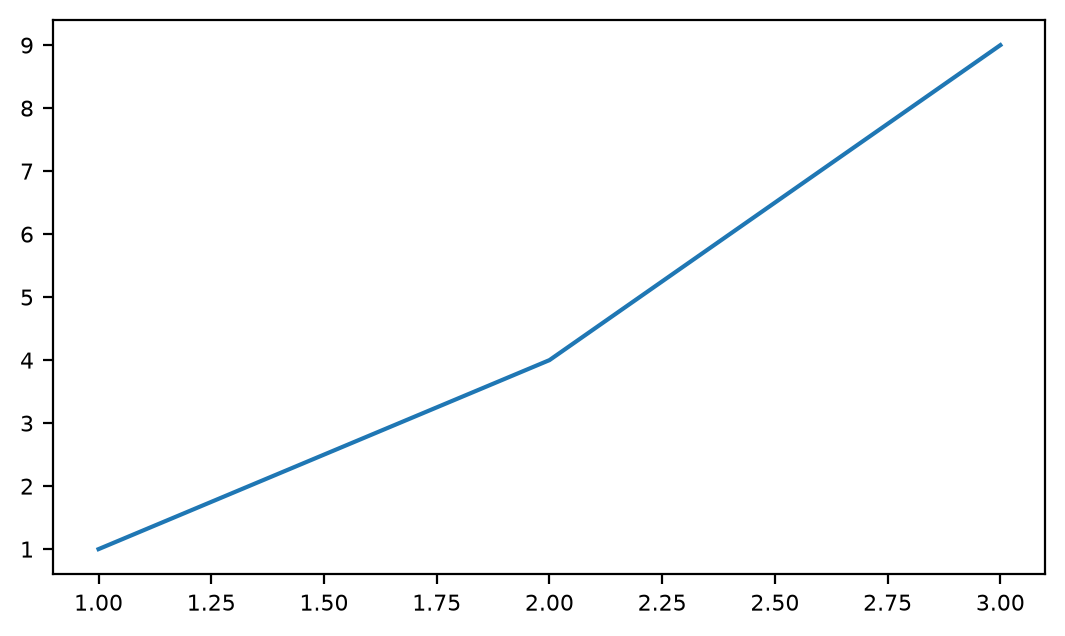

In [5]:
plt.plot([1, 2, 3], [1, 4, 9])

With a trailing semicolon, only the figure is shown:

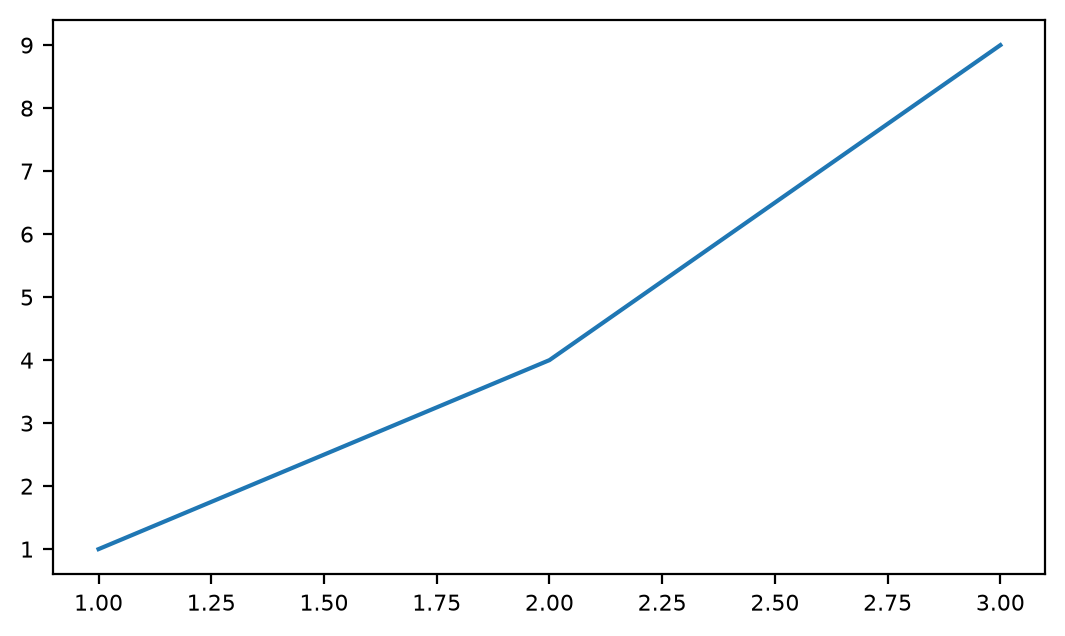

In [6]:
plt.plot([1, 2, 3], [1, 4, 9]);

*See also:* Finishing a figure with `plt.show()` (C1) · Drawing a line plot (C3) · Running a cell (A1)

#### Restarting the kernel and running all cells

**A1.03**

`Kernel > Restart & Run All`

Restarting the kernel and running all cells allows us to check that a notebook works from top to bottom with a clean memory. It is useful before work is submitted, or when results look unexpected after cells have been run out of order.

Jupyter remembers every variable that has been created, even if the cell that made it is later deleted, or if cells are run out of order. The menu command **Kernel → Restart Kernel and Run All Cells** clears that memory and runs the notebook from the top.

The cells below show the problem. Run once, the second cell gives 20:

In [7]:
x = 10

In [8]:
x = x * 2
x

20

Run a second time, the same cell doubles the *current* value of `x`, so the result depends on how many times the cell has been run:

In [9]:
x = x * 2   # the same cell, run again
x

40

*See also:* Running a cell (A1) · NameError: name is not defined (A1) · Updating a variable with `+=` and `abs()` (A1)

#### Installing a package with `%pip`

**A1.04**

`%pip install statsmodels`

The `%pip` command allows us to install a missing package into the environment that the notebook is using. It is useful when `ModuleNotFoundError` appears. Alternatively, run `pip install` in a terminal and then restart the kernel.

`%pip` installs into the environment in which the notebook is running. It is run once, followed by a kernel restart. The command is commented out here so that this textbook does not reinstall anything.

In [10]:
# Run this once (remove the #), then Kernel > Restart:
# %pip install statsmodels

import statsmodels
print(f"statsmodels version: {statsmodels.__version__}")

statsmodels version: 0.15.0


*See also:* Fitting a model with a formula (D5) · Running a cell (A1) · Importing pandas (B1)

### Numbers and arithmetic

#### Basic arithmetic

**A1.05**

`+ - * /`

The operators `+ - * /` allow us to do ordinary arithmetic in Python. They are useful for any calculation that could be done on a calculator. Alternatively, functions such as `sum()` add up a whole list of numbers.

Each line below is shown as its own cell, as in a notebook. Watch out: `/` always gives a decimal answer, even when the division is exact.

In [11]:
print(7 + 2)
print(7 - 2)
print(7 * 2)
print(7 / 2)
print(8 / 2)    # still a decimal: 4.0

9
5
14
3.5
4.0


*See also:* Calculating powers and square roots (A1) · Dividing with `//` and `%` (A1) · Controlling the order of operations (A1)

#### Calculating powers and square roots

**A1.06**

`x ** 2, x ** 0.5`

The `**` operator allows us to raise a number to a power, including `0.5` for a square root. It is useful for squares, growth formulas and standard deviations. Alternatively, `np.sqrt()` gives square roots and also works on whole arrays.

`**` means "to the power of". A power of 0.5 is a square root; a power of −1 is a reciprocal.

In [12]:
print(23 ** 2)     # 23 squared
print(2 ** 10)     # 1024
print(81 ** 0.5)   # square root of 81
print(10 ** -1)    # 0.1

529
1024
9.0
0.1


*See also:* Basic arithmetic (A1) · Applying maths functions to an array (A4) · Controlling the order of operations (A1)

#### Dividing with `//` and `%`

**A1.07**

`a // b, a % b`

The `//` and `%` operators allow us to split a number into whole groups and a remainder. They are useful for converting units (minutes to hours) or for checking whether a number is even (`n % 2 == 0`). Alternatively, `divmod(a, b)` returns both at once.

`//` gives how many whole times `b` fits into `a`; `%` gives what is left over. Together they split 100 minutes into hours and minutes.

In [13]:
16 // 5   # 3 whole fives

3

In [14]:
16 % 5    # remainder 1

1

In [15]:
minutes = 100
print(f"{minutes // 60} hour(s) and {minutes % 60} minutes")

1 hour(s) and 40 minutes


*See also:* Basic arithmetic (A1) · Calculating powers and square roots (A1) · Controlling the order of operations (A1)

#### Writing big numbers and scientific notation

**A1.08**

`100_000_000, 1e9, 1.23e-5`

Underscores and `e` notation allow us to write very large or very small numbers clearly. They are useful for populations, concentrations and any number with many zeros. Alternatively, write the full number, but the zeros can be miscounted.

Underscores make a long number readable and are ignored by Python. `1e9` means 1 × 10⁹ and `1.23e-5` means 1.23 × 10⁻⁵.

In [16]:
population = 100_000_000
population

100000000

In [17]:
print(1e9)

1000000000.0


In [18]:
print(1.23e-5)

1.23e-05


In [19]:
1000000000.0 == 1000000000

True

*See also:* Formatting numbers in an f-string (A1) · Basic arithmetic (A1)

#### Controlling the order of operations

**A1.09**

`(a + b) * c`

Python's operator precedence determines which part of a calculation is done first, and brackets override it. It is useful when a formula gives an unexpected answer. Alternatively, store intermediate results in variables so that each step is clear.

Python follows the usual rules: brackets, then powers, then multiplication and division, then addition and subtraction. Use brackets to make the intended order clear.

In [20]:
print(2 + 3 * 4)       # multiplication first: 14
print((2 + 3) * 4)     # brackets first: 20
print(-3 ** 2)         # the power is applied before the minus sign: -9
print((-3) ** 2)       # 9

14
20
-9
9


*See also:* Basic arithmetic (A1) · Calculating powers and square roots (A1)

### Variables, types and conversion

#### Creating a variable

**A1.10**

`x = 5`

The `=` sign allows us to store a value under a name so that it can be reused. It is useful whenever a number appears more than once or needs a meaningful label. Alternatively, type the number each time, but changing it later is much harder.

`=` stores a value under a name (it is not a mathematical "equals"). The name can be used afterwards and can be reassigned; the old value is then forgotten.

In [21]:
mass_kg = 12.5      # a comment explains the code
n_fish = 3
mass_kg * n_fish

37.5

In [22]:
n_fish = 4          # reassign: the old value (3) is forgotten
mass_kg * n_fish

50.0

*See also:* Checking the type of a value (A1) · Printing several values (A1) · Converting between types (A1)

#### Checking the type of a value

**A1.11**

`type(x)`

The `type()` function allows us to see what type of value a variable holds. It is useful when code fails with a `TypeError`, or when a number is stored as text. Alternatively, `df.dtypes` shows the type of every column of a DataFrame.

Python has several types of value: `int` (whole numbers), `float` (decimals), `str` (text) and `bool` (True or False).

In [23]:
print(type(5))
print(type(5.0))
print(type("five"))
print(type(True))
print(type(5 / 1))   # division always gives a float

<class 'int'>
<class 'float'>
<class 'str'>
<class 'bool'>
<class 'float'>


*See also:* Checking the column types (B1) · Converting between types (A1) · TypeError: wrong type for an operation (A1)

#### Converting between types

**A1.12**

`int(x), float(x), str(x)`

The functions `int()`, `float()` and `str()` allow us to change a value from one type to another. They are useful when numbers arrive as text, or when a number is needed inside a message. Alternatively, `.astype()` converts a whole pandas column.

Before: text that looks like a number has type `str`, so arithmetic fails.

In [24]:
value = "12"
type(value)

str

After `int()`, the same digits are a number and arithmetic works.

In [25]:
number = int(value)
type(number)

int

In [26]:
number + 1

13

Watch out: `int()` truncates towards zero; it does not round.

In [27]:
int(7.9)

7

In [28]:
int(-7.9)

-7

`float()` and `str()` convert in the other directions:

In [29]:
float(3)

3.0

In [30]:
str(42) + " is a string"

'42 is a string'

*See also:* Changing a column's type (B2) · Checking the type of a value (A1) · Rounding a number (A1) · TypeError: wrong type for an operation (A1)

#### Rounding a number

**A1.13**

`round(x, n)`

The `round(x, n)` function allows us to round a number to `n` decimal places. It is useful for tidying results before they are reported. Alternatively, an f-string such as `{x:.2f}` rounds only the *display*, leaving the stored value unchanged.

A negative `n` rounds to tens, hundreds and so on. `int()` only removes the decimals, so it is shown for comparison.

In [31]:
x = 12.836
x

12.836

In [32]:
round(x)          # nearest whole number

13

In [33]:
round(x, 1)       # 1 decimal place

12.8

In [34]:
round(124.4, -1)  # nearest ten

120.0

In [35]:
int(x)            # truncates: 12

12

*See also:* Formatting numbers in an f-string (A1) · Converting between types (A1) · Showing thousands separators and percentages (A1)

#### Updating a variable with `+=` and `abs()`

**A1.14**

`x += 1, abs(x)`

***(non-examinable)***

Operators such as `+=` allow us to update a variable in place, and `abs()` removes a minus sign. They are useful for counters and running totals. Alternatively, write the long form `x = x + 1`, which has the same effect.

`x += 1` means `x = x + 1`. The same pattern works with `-=`, `*=` and `/=`. The value of `x` is displayed after each update.

In [36]:
x = 10
print(x)
x += 5     # add 5
print(x)
x *= 2     # multiply by 2
print(x)
x -= 1     # subtract 1
print(x)

10
15
30
29


In [37]:
abs(-3.2)

3.2

*See also:* Updating a value on each pass (A2) · Creating a variable (A1)

### Output

#### Printing several values

**A1.15**

`print(a, b)`

The `print()` function allows us to show text and values, separated by spaces. It is useful for checking what a variable holds or for reporting a result inside a loop. Alternatively, an f-string gives more control over the layout.

`print` puts a space between comma-separated items, and each call starts a new line. Use `end=""` or `end=" "` to continue on the same line.

In [38]:
mass_kg = 12.5
print("mass =", mass_kg, "kg")
print("a", "b", "c")
print("same", end=" ")
print("line")

mass = 12.5 kg
a b c
same line


*See also:* Building text with an f-string (A1) · Formatting numbers in an f-string (A1) · Checking a value with `print()` (A1)

#### Building text with an f-string

**A1.16**

`f"w = {w}"`

An f-string allows us to put variables and calculations directly inside a piece of text. It is useful for readable messages with values inside. Alternatively, `+` with `str()` joins text and numbers, but every number must be converted first.

Put `f` before the quotation marks and write variables or calculations inside `{}`.

In [39]:
name = "cod"
mass_kg = 12.5
print(f"The {name} has a mass of {mass_kg} kg")

The cod has a mass of 12.5 kg


In [40]:
print(f"Twice that mass is {mass_kg * 2} kg")

Twice that mass is 25.0 kg


*See also:* Formatting numbers in an f-string (A1) · Printing several values (A1)

#### Formatting numbers in an f-string

**A1.17**

`{x:.1f}  {x:.3g}  {x:.2e}`

Format codes after a colon allow us to control how a number is displayed: decimals (`.1f`), significant figures (`.3g`) or scientific notation (`.2e`). They are useful for reporting results neatly. Alternatively, `round()` changes the value itself rather than only its display.

After a colon, the display of the number is specified: `.1f` = 1 decimal place, `.3g` = 3 significant figures, `.2e` = scientific notation. This changes how the number is *displayed*, not its value.

In [41]:
x = 1234.56789
x

1234.56789

In [42]:
print(f"{x:.1f}")

1234.6


In [43]:
print(f"{x:.3g}")

1.23e+03


In [44]:
print(f"{x:.2e}")

1.23e+03


Significant figures also suit small numbers:

In [45]:
p = 0.000123456
print(f"{p:.3g}")

0.000123


*See also:* Building text with an f-string (A1) · Rounding a number (A1) · Writing big numbers and scientific notation (A1) · Starting a new line in text (A1) · Reporting values to a sensible precision (D6)

#### Starting a new line in text

**A1.18**

`"\n"`

The `\n` character allows us to start a new line inside one piece of text. It is useful for multi-line messages from a single `print`. Alternatively, call `print()` several times.

`\n` inside a string starts a new line (`\t` is a tab). Without `print`, the escape sequence is shown as typed:

In [46]:
"first line\nsecond line"

'first line\nsecond line'

With `print`, the line break is applied:

In [47]:
print("first line\nsecond line")

first line
second line


In [48]:
print("name\tvalue")

name	value


*See also:* Building text with an f-string (A1) · Showing thousands separators and percentages (A1)

#### Showing thousands separators and percentages

**A1.19**

`{x:,}  {p:.1%}`

***(non-examinable)***

Format codes `,` and `%` allow us to display `1,000,000` or `12.5%`. They are useful when reporting large numbers or probabilities. Alternatively, multiply by 100 and add a `%` sign as text.

In [49]:
n = 1234567.891
p = 0.125
print(f"{n:,}")

1,234,567.891


In [50]:
print(f"{n:,.2f}")

1,234,567.89


In [51]:
print(f"{p:.1%}")     # a probability shown as a percentage

12.5%


*See also:* Formatting numbers in an f-string (A1) · Building text with an f-string (A1) · Asking for help with `help()` (A1)

#### Asking for help with `help()`

**A1.20**

`help(func)`

***(non-examinable)***

The `help()` function allows us to read the documentation of any function without leaving Jupyter. It is useful when the arguments of a function are not remembered. Alternatively, type `func?` in a cell, or search the online documentation.

In Jupyter, `help(round)` (or `round?`) shows the documentation for any function.

In [52]:
help(round)

Help on built-in function round in module builtins:

round(number, ndigits=None)
    Round a number to a given precision in decimal digits.

    The return value is an integer if ndigits is omitted or None.
    Otherwise the return value has the same type as the number.  ndigits
    may be negative.



*See also:* Rounding a number (A1) · Checking the type of a value (A1) · Checking the type, size and contents of an object (A1)

### Common error messages

#### NameError: name is not defined

**A1.21**

`NameError: name 'x' is not defined`

A `NameError` tells us that Python does not recognise a name; the usual causes are a typo or a cell that has not been run.

A name was used that does not exist: a typo, or the cell that creates it has not been run. Read the last line of the message first.

In [53]:
total_mass = 5
totl_mass    # typo: should be total_mass

NameError: name 'totl_mass' is not defined

Fixed:

In [54]:
total_mass = 5
total_mass

5

Note: *Restart & Run All* rules out an out-of-date kernel.

*See also:* Restarting the kernel and running all cells (A1) · KeyError: key not found (A1) · Creating a variable (A1)

#### IndentationError: unexpected indent

**A1.22**

`IndentationError`

An `IndentationError` tells us that the indentation of a block is missing or inconsistent, usually after a line starting with `if`, `for` or `def`.

Code inside `if` or `for` must be indented consistently (four spaces is standard). The faulty code is passed to `exec` here so that the error can be shown without stopping the notebook.

In [55]:
exec("for i in range(3):\nprint(i)")   # print is not indented

IndentationError: expected an indented block after 'for' statement on line 1 (<string>, line 2)

Fixed:

In [56]:
for i in range(3):
    print(i)

0
1
2


Note: pressing `Tab` lets Jupyter indent consistently.

*See also:* Choosing with `if` and `else` (A2) · Repeating n times with `range(n)` (A2) · Writing a function with `def` (A2)

#### IndexError: index out of range

**A1.23**

`IndexError: list index out of range`

An `IndexError` tells us that a position beyond the end of a list was requested, often by a loop or an index that runs one past the end.

A list of three items has positions 0, 1 and 2. Asking for position 3 fails.

In [57]:
mylist = [10, 20, 30]
mylist[3]

IndexError: list index out of range

Fixed:

In [58]:
mylist = [10, 20, 30]
mylist[2]    # the last item

30

In [59]:
mylist[-1]   # also the last item

30

In [60]:
len(mylist)

3

Note: `my_list[-1]` always gives the last item, and `len()` gives the number of items.

*See also:* Picking an item from a list by position (A3) · NameError: name is not defined (A1)

#### KeyError: key not found

**A1.24**

`KeyError: 'colname'`

A `KeyError` tells us that a dictionary key or DataFrame column name does not exist; capital letters and spaces are the common causes.

A dictionary key or DataFrame column name does not exist. Check the spelling and capital letters with `df.columns`.

In [61]:
df_penguins["Species"]    # the column is called 'species'

KeyError: 'Species'

Fixed:

In [62]:
df_penguins.columns.tolist()

['species',
 'island',
 'bill_length_mm',
 'bill_depth_mm',
 'flipper_length_mm',
 'body_mass_g',
 'sex']

In [63]:
# display example data
df_penguins["species"].head(3)

0    Adelie
1    Adelie
2    Adelie
Name: species, dtype: object

Note: printing `df.columns` shows the exact names.

*See also:* Selecting one column (B2) · Looking up a value in a dictionary (A3)

#### TypeError: wrong type for an operation

**A1.25**

`TypeError`

A `TypeError` tells us that an operation does not work on the types given, such as adding text to a number, usually because data are stored as the wrong type.

A string and a number cannot be added. One of them must be converted so that both have the same type.

In [64]:
"5" + 3

TypeError: can only concatenate str (not "int") to str

Fixed (two ways):

In [65]:
int('5') + 3     # numbers

8

In [66]:
'5' + str(3)     # text

'53'

Note: converting with `int()`, `float()` or `str()` first fixes it.

*See also:* Checking the type of a value (A1) · Converting between types (A1) · Checking the type, size and contents of an object (A1)

### Checking values and assumptions

#### Checking a value with `print()`

**A1.26**

`print(f"x = {x}")`

***(non-examinable)***

Printing a value at chosen points allows us to see what a variable holds while the code runs. It is useful for finding where a calculation goes wrong. Alternatively, a Jupyter cell displays the value of its last line without `print`.

A label that names the variable makes the output clearer than a bare number. The inputs are checked first, then the result.

In [67]:
mass_kg = 12.5
n_fish = 3
print(f"mass_kg = {mass_kg}")

mass_kg = 12.5


In [68]:
print(f"n_fish = {n_fish}")

n_fish = 3


In [69]:
total_kg = mass_kg * n_fish
print(f"total_kg = {total_kg}")

total_kg = 37.5


*See also:* Printing several values (A1) · Building text with an f-string (A1) · Splitting a calculation into steps to find an error (A1) · Testing an assumption with `assert` (A1)

#### Checking the type, size and contents of an object

**A1.27**

`type(x), len(x), repr(x)`

***(non-examinable)***

Checking the type, the length and the contents of an object allows us to confirm that it is what the code assumes. It is useful when a result looks wrong, because text that looks like a number, or an empty list, causes many errors. Alternatively, `help(obj)` and `dir(obj)` list what an object can do.

In [70]:
values = ["12", "15", " 8 "]
type(values)                 # a list

list

In [71]:
len(values)                  # three items

3

In [72]:
# display example data
values                       # the quotation marks show that these are text, not numbers

['12', '15', ' 8 ']

In [73]:
repr(values[2])              # repr makes the hidden spaces visible

"' 8 '"

*See also:* Asking for help with `help()` (A1) · Checking the type of a value (A1) · Converting between types (A1) · Checking a DataFrame after each step (B1)

#### Splitting a calculation into steps to find an error

**A1.28**

`step1 = ...; step1`

***(non-examinable)***

Breaking a long expression into named steps and checking each one allows us to find which part gives an unexpected value. It is useful when a formula returns a wrong answer without an error message. Alternatively, test the formula with simple numbers whose answer is known.

One long expression gives a result, but it may not be the intended one:

In [74]:
a, b, c = 2, 3, 4
a + b * c / 2

8.0

Each step can be named and displayed:

In [75]:
step1 = b * c
step1                              # 12

12

In [76]:
step2 = step1 / 2
step2                              # 6.0

6.0

In [77]:
a + step2                          # the multiplication and division happen before the addition

8.0

Brackets give the intended order of operations:

In [78]:
(a + b) * c / 2

10.0

*See also:* Controlling the order of operations (A1) · Checking a value with `print()` (A1) · Checking a new column against a hand calculation (B1)

#### Testing an assumption with `assert`

**A1.29**

`assert condition, "message"`

***(non-examinable)***

An `assert` statement allows us to state what must be true and stops the code with an error if it is not. It is useful for catching problems early. Alternatively, an `if` statement with `print` reports a problem without stopping the code.

When the condition is true, `assert` does nothing:

In [79]:
values = [4, 8, 15, 16]
assert len(values) == 4, "expected 4 values"
len(values)

4

When the condition is false, an `AssertionError` is raised with the message:

In [80]:
assert len(values) == 5, "expected 5 values"

AssertionError: expected 5 values

*See also:* Checking the type, size and contents of an object (A1) · Comparing values (A2)